## Configuracion vigente del modelado

La comparacion y el entrenamiento final se realizan **sin SMOTE**. Antes de comparar modelos se elimina redundancia con correlacion absoluta mayor que 0,95 y se seleccionan 10 columnas mediante `SequentialFeatureSelector` forward con `LinearRegression`, usada solo como filtro de predictores. La prioridad de seleccion es Recall y el modelo final es un **SVM lineal con class_weight='balanced'**. Optuna ajusta unicamente C manteniendo esa configuracion. Las salidas almacenadas de ejecuciones anteriores deben regenerarse ejecutando las celdas.


# Modelado y evaluación de churn

## Propósito y recorrido
Este cuaderno consume matrices CSV ya procesadas y transformadas. La secuencia es: comparar candidatos con validación cruzada en train, ajustar el candidato con Optuna, fijar un único modelo y cargar el test transformado una sola vez para reportarlo al final. Después interpreta el ranking y el score con gráficos, permutación y SHAP.

**Para público administrativo:** el Recall responde cuántos abandonos históricos se detectaron; la precisión, qué proporción de los clientes señalados sí abandonó. **Para público técnico:** el score SVM es `decision_function`, no una probabilidad calibrada.

La selección programática no consulta test. Aun así, el cuaderno EDA describe la cohorte completa, por lo que el test no es completamente ciego frente a decisiones humanas informadas por la exploración. Para una afirmación confirmatoria se requiere una cohorte nueva o temporal no explorada.


## 1. Preparar datos 

Esta etapa carga los CSV transformados de train y mantiene el test fuera del cuaderno hasta la evaluación final. Las transformaciones se ajustaron durante la generación de `data/processed/` usando solo train; la comparación CV y Optuna trabajan únicamente con las matrices de entrenamiento.


In [1]:
import os

os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.svm import SVC

from src.modeling import (
    CORRELATION_THRESHOLD,
    REDUCED_FEATURE_COUNT,
    save_model_artifact,
    select_model,
    select_reduced_features,
)
from src.paths import FIGURES_DIR, RESULTS_DIR
from src.pipeline import TARGET, build_processed_evaluation_pipeline
from src.processed_data import load_processed_split

RANDOM_STATE = 42
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# El modelado consume solo matrices ya transformadas.
# El test no se carga durante la selección de modelos.
X_train, y_train = load_processed_split('train', representation='original')
feature_selection = select_reduced_features(
    X_train,
    y_train,
    correlation_threshold=CORRELATION_THRESHOLD,
    n_features_to_select=REDUCED_FEATURE_COUNT,
    random_state=RANDOM_STATE,
)
X_train_reduced = X_train[feature_selection.selected_features]
X = X_train_reduced
print(
    f'Train transformado: {len(X_train):,}; '
    f'variables originales transformadas: {X_train.shape[1]:,}; '
    f'variables seleccionadas: {X_train_reduced.shape[1]:,}'
)
print(f'Churn train: {y_train.mean():.3%}')
print(f'Eliminadas por correlación: {len(feature_selection.dropped_correlated)}')
print(f'Variables SFS: {feature_selection.selected_features}')
print('El test procesado se cargará únicamente en la celda de evaluación final.')

Train transformado: 5,617; variables originales transformadas: 46; variables seleccionadas: 10
Churn train: 26.651%
Eliminadas por correlación: 13
Variables SFS: ['power__TotalCharges', 'standard__tenure', 'categorical__MultipleLines_No', 'categorical__InternetService_DSL', 'categorical__InternetService_Fiber optic', 'categorical__StreamingTV_No', 'categorical__StreamingMovies_No', 'categorical__Contract_Month-to-month', 'categorical__PaperlessBilling_No', 'categorical__PaymentMethod_Electronic check']
El test procesado se cargará únicamente en la celda de evaluación final.


### Cierre de la sección 1: cohorte y partición

La versión procesada contiene **5.617 filas para entrenamiento** y **1.408 para test reservado**. La matriz original codificada tiene 46 columnas; después del filtro de correlación y SFS, el modelo reducido utiliza 10.

Las proporciones similares confirman la estratificación. Esta partición protege el flujo de selección frente al uso programático del test; la exploración humana de la cohorte completa en el cuaderno 01 se reconoce como limitación y no como una separación ciega absoluta.

**Lo que conviene matizar:**
- "Variables eliminadas" no significa "variables que no sirven"; significa "variables descartadas por el criterio del filtro de ese momento".
- La selección es un paso de model selection, no un resultado causal o interpretativo final.
- El objetivo del filtro es mejorar robustez y reducir ruido, no "descubrir verdad"; por eso la interpretación debe mantenerse descriptiva.
- La comparación final se hace con CV sobre train y el test se usa solo al final para reportar desempeño.


## Estrategia de optimización: baseline, Lazy Predict, tuning, calibración y riesgo

La estrategia de mejora del modelo se centra en tres pilares: mantener la versión actual como respaldo, comparar candidatos con validación cruzada usando Recall y PR-AUC como prioridad, y calibrar la salida para convertir el score del modelo en probabilidad útil para negocio.

La lógica final será:
- guardar el pipeline actual como baseline de respaldo
- testar varios modelos con Lazy Predict
- revisar los mejores candidatos con Random Search y Grid Search
- calibrar la salida del mejor modelo
- ajustar un umbral de negocio por riesgo operativo
- devolver clase binaria, score, probabilidad 0-1, porcentaje 0-100 y nivel de riesgo
- guardar evidencia del proceso en gráficos y CSV para uso documental posterior

Esto permite comparar la versión actual con la mejor versión posible sin perder la referencia original.


**Configuracion aplicada:** sin SMOTE; el SVM lineal usa class_weight='balanced' y Recall es la metrica prioritaria.

## 2. Comparación de modelos solo con entrenamiento

Se comparan un baseline Dummy, modelos supervisados y la representación PCA/K-Means con los mismos folds estratificados. La tabla resume Recall y ROC-AUC; como la prioridad declarada es detectar churn, Recall guía la selección y ROC-AUC aporta una lectura de ordenamiento a distintos umbrales. El conjunto de prueba no interviene.


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Lazy Predict requiere una versión compatible con scikit-learn 1.8+.
# En este proyecto la versión válida es lazypredict >= 0.4.0.
try:
    import sklearn
    import lazypredict
    from lazypredict.Supervised import LazyClassifier

    print(f'scikit-learn={sklearn.__version__}')
    print(f'lazypredict={lazypredict.__version__}')

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_reduced,
        y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )

    # Importante: LazyClassifier.fit exige el orden:
    # fit(X_train, X_test, y_train, y_test)
    lazy_model = LazyClassifier(verbose=0, ignore_warnings=True)
    lazy_models, _ = lazy_model.fit(X_fit, X_val, y_fit, y_val)
    lazy_summary = lazy_models.reset_index().rename(columns={'index': 'model'})
    lazy_summary = lazy_summary[[
        'model', 'Accuracy', 'Balanced Accuracy', 'ROC AUC', 'F1 Score', 'Precision', 'Recall', 'Time Taken'
    ]]
    lazy_summary = lazy_summary.sort_values(['Recall', 'ROC AUC'], ascending=[False, False]).reset_index(drop=True)
    lazy_summary.to_csv(RESULTS_DIR / 'lazy_predict_recall_cv.csv', index=False)
    print('Comparación Lazy Predict guardada en output/resultados/lazy_predict_recall_cv.csv')
    display(lazy_summary.head(10))
except Exception as exc:
    print('Lazy Predict no está disponible o es incompatible con este entorno.')
    print(f'Detalle: {exc}')
    print('Solución recomendada: usar lazypredict>=0.4.0 con scikit-learn>=1.8 y ejecutar la celda desde el entorno del proyecto.')

# Candidatos para búsqueda de hiperparámetros
candidate_specs = {
    'log_reg': LogisticRegression(class_weight='balanced', max_iter=3000, random_state=RANDOM_STATE),
    'svm_linear': SVC(kernel='linear', class_weight='balanced', probability=False, random_state=RANDOM_STATE),
    'rf': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'hgb': HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_depth=6, learning_rate=0.05),
}


scikit-learn=1.9.1
lazypredict=0.4.0


Lazy Predict no está disponible o es incompatible con este entorno.
Detalle: "['model'] not in index"
Solución recomendada: usar lazypredict>=0.4.0 con scikit-learn>=1.8 y ejecutar la celda desde el entorno del proyecto.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

try:
    import sklearn
    import lazypredict
    from lazypredict.Supervised import LazyClassifier

    print(f"scikit-learn={sklearn.__version__}")
    print(f"lazypredict={lazypredict.__version__}")

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_reduced,
        y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )

    lazy_model = LazyClassifier(verbose=0, ignore_warnings=True)
    lazy_models, _ = lazy_model.fit(X_fit, X_val, y_fit, y_val)

    lazy_summary = lazy_models.reset_index().rename(columns={"index": "model"})
    lazy_summary = lazy_summary[
        [
            "model",
            "Accuracy",
            "Balanced Accuracy",
            "ROC AUC",
            "F1 Score",
            "Precision",
            "Recall",
            "Time Taken",
        ]
    ]
    lazy_summary = lazy_summary.sort_values(
        ["Recall", "ROC AUC"],
        ascending=[False, False],
    ).reset_index(drop=True)

    lazy_summary.to_csv(RESULTS_DIR / "lazy_predict_recall_cv.csv", index=False)
    print("Comparación Lazy Predict guardada en output/resultados/lazy_predict_recall_cv.csv")
    display(lazy_summary.head(10))

except ModuleNotFoundError as exc:
    print("Lazy Predict no está instalado en este kernel.")
    print(f"Detalle: {exc}")
    print("Solución: activa el entorno del proyecto y ejecuta: pip install lazypredict==0.4.0")
    print("o usa: conda run -n telco-ml python ...")

except Exception as exc:
    print("Lazy Predict falló por incompatibilidad o error de llamada.")
    print(f"Detalle: {exc}")
    print("Revisa que estés usando el kernel telco-ml y que la llamada sea fit(X_train, X_test, y_train, y_test).")

scikit-learn=1.9.1
lazypredict=0.4.0


Lazy Predict falló por incompatibilidad o error de llamada.
Detalle: "['model'] not in index"
Revisa que estés usando el kernel telco-ml y que la llamada sea fit(X_train, X_test, y_train, y_test).



## 3. Optuna final: búsqueda de hiperparámetros sobre la mejor variante del modelo

La comparación inicial con Lazy Predict y el tuning rápido de candidatos sirve para detectar la familia de modelos más prometedora. Una vez identificada la mejor variante, Optuna puede afinar la configuración con una métrica más coherente con el negocio: Recall + PR-AUC.

La regla se mantiene consistente con la estrategia del proyecto:
- solo se usa train para la optimización
- no se mira test durante el ajuste
- la métrica objetivo prioriza detectar churn
- el modelo ganador se conservará como referencia para calibración y decisión final


In [4]:
try:
    import optuna
except ImportError:
    optuna = None
    print('Optuna no está instalado en este entorno. La celda queda preparada para ejecutarse cuando el paquete esté disponible.')

if optuna is not None:
    def make_model_from_params(model_name, params):
        if model_name == 'logreg':
            return LogisticRegression(
                C=float(params['logreg_C']),
                class_weight='balanced',
                max_iter=4000,
                random_state=RANDOM_STATE,
            )
        if model_name == 'svm':
            return SVC(
                C=float(params['svm_C']),
                kernel=params['svm_kernel'],
                class_weight='balanced',
                probability=False,
                random_state=RANDOM_STATE,
            )
        if model_name == 'rf':
            return RandomForestClassifier(
                n_estimators=int(params['rf_n_estimators']),
                max_depth=params['rf_max_depth'],
                min_samples_leaf=int(params['rf_min_samples_leaf']),
                max_features=params['rf_max_features'],
                class_weight='balanced',
                random_state=RANDOM_STATE,
            )
        if model_name == 'hgb':
            return HistGradientBoostingClassifier(
                learning_rate=float(params['hgb_learning_rate']),
                max_depth=int(params['hgb_max_depth']),
                max_leaf_nodes=int(params['hgb_max_leaf_nodes']),
                min_samples_leaf=int(params['hgb_min_samples_leaf']),
                random_state=RANDOM_STATE,
            )
        raise ValueError(f'Modelo no soportado: {model_name}')

    def objective(trial):
        model_name = trial.suggest_categorical('model_name', ['logreg', 'svm', 'rf', 'hgb'])

        if model_name == 'logreg':
            params = {
                'logreg_C': trial.suggest_float('logreg_C', 0.05, 2.0, log=True),
            }
        elif model_name == 'svm':
            params = {
                'svm_C': trial.suggest_float('svm_C', 0.05, 3.0, log=True),
                'svm_kernel': trial.suggest_categorical('svm_kernel', ['linear', 'rbf']),
            }
        elif model_name == 'rf':
            params = {
                'rf_n_estimators': trial.suggest_int('rf_n_estimators', 200, 500),
                'rf_max_depth': trial.suggest_categorical('rf_max_depth', [None, 4, 6, 8, 12]),
                'rf_min_samples_leaf': trial.suggest_int('rf_min_samples_leaf', 1, 6),
                'rf_max_features': trial.suggest_categorical('rf_max_features', ['sqrt', 'log2', None]),
            }
        else:
            params = {
                'hgb_learning_rate': trial.suggest_float('hgb_learning_rate', 0.01, 0.2, log=True),
                'hgb_max_depth': trial.suggest_int('hgb_max_depth', 3, 12),
                'hgb_max_leaf_nodes': trial.suggest_int('hgb_max_leaf_nodes', 15, 60),
                'hgb_min_samples_leaf': trial.suggest_int('hgb_min_samples_leaf', 5, 30),
            }

        estimator = make_model_from_params(model_name, params)
        recall_scores = cross_val_score(
            estimator,
            X_train_reduced,
            y_train,
            cv=cv,
            scoring=make_scorer(recall_score, pos_label=1),
            n_jobs=1,
        )
        pr_auc_scores = cross_val_score(
            estimator,
            X_train_reduced,
            y_train,
            cv=cv,
            scoring='average_precision',
            n_jobs=1,
        )
        objective_score = float(recall_scores.mean() + pr_auc_scores.mean())
        return objective_score

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(objective, n_trials=25, show_progress_bar=False)

    best_name = study.best_trial.params['model_name']
    best_params = {k: v for k, v in study.best_trial.params.items() if k != 'model_name'}
    best_model = make_model_from_params(best_name, best_params)
    best_model.fit(X_train_reduced, y_train)

    trial_df = study.trials_dataframe()
    trial_df.to_csv(RESULTS_DIR / 'optuna_recall_pr_auc.csv', index=False)
    joblib.dump(best_model, PROJECT_ROOT / 'output' / 'modelos' / 'telco_churn_model_optuna.joblib')

    print('Optuna: mejor modelo por Recall + PR-AUC')
    print(f'Modelo ganador: {best_name}')
    print(f'Parámetros: {best_params}')
    print(f'Valor objetivo: {study.best_value:.4f}')
    display(trial_df.sort_values('value', ascending=False).head(10))

    calibrated_best = CalibratedClassifierCV(estimator=best_model, method='sigmoid', cv=cv)
    calibrated_best.fit(X_train_reduced, y_train)
    calibrated_prob = calibrated_best.predict_proba(X_train_reduced)[:, 1]
    threshold_summary = []
    for threshold in np.linspace(0.30, 0.80, 51):
        pred = (calibrated_prob >= threshold).astype(int)
        threshold_summary.append({
            'threshold': round(float(threshold), 4),
            'recall': float(recall_score(y_train, pred, pos_label=1, zero_division=0)),
            'precision': float(precision_score(y_train, pred, pos_label=1, zero_division=0)),
            'f1': float(f1_score(y_train, pred, pos_label=1, zero_division=0)),
            'average_precision': float(average_precision_score(y_train, calibrated_prob)),
            'roc_auc': float(roc_auc_score(y_train, calibrated_prob)),
        })

    threshold_summary_df = pd.DataFrame(threshold_summary)
    threshold_summary_df = threshold_summary_df.sort_values(['recall', 'f1', 'precision'], ascending=[False, False, False])
    threshold_summary_df.to_csv(RESULTS_DIR / 'optuna_threshold_business_calibration.csv', index=False)
    display(threshold_summary_df.head(10))

else:
    print('Optuna no se ejecutó porque no está instalado en este entorno. La siguiente etapa es instalarlo y ejecutar esta sección en el entorno del proyecto.')


[I 2026-11-16 17:54:44,683] A new study created in memory with name: no-name-bde7c62c-3c8b-4902-b2cb-ee6b4d8a94cc


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (155 outputs left out)

C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,threshold,recall,precision,f1,average_precision,roc_auc
0,0.30,0.830995,0.466617,0.597646,0.658212,0.840791
1,0.31,0.830327,0.467997,0.598603,0.658212,0.840791
2,0.32,0.828991,0.470254,0.600097,0.658212,0.840791
3,0.33,0.825651,0.472297,0.600875,0.658212,0.840791
4,0.34,0.821643,0.476006,0.602793,0.658212,0.840791
5,0.35,0.816967,0.480361,0.604996,0.658212,0.840791
6,0.36,0.814963,0.486832,0.609543,0.658212,0.840791
7,0.37,0.807615,0.494883,0.613706,0.658212,0.840791
8,0.38,0.800935,0.501254,0.616611,0.658212,0.840791
9,0.39,0.791583,0.512100,0.621884,0.658212,0.840791


In [5]:
selection = select_model(
    X_train_reduced,
    y_train,
    data_is_processed=True,
    include_pca_kmeans=False,
    random_state=RANDOM_STATE,
    n_trials=5,
    timeout=240,
)
cv_results = selection.cv_results
model_specs = selection.model_specs
selected_name = selection.selected_name
selected_classifier = selection.selected_classifier
selected_representation = selection.selected_representation
selected_smote = selection.selected_smote
selected_train_features = X_train_reduced

assert selected_smote is False, 'La seleccion final no debe utilizar SMOTE.'
assert getattr(selected_classifier, 'class_weight', None) == 'balanced', (
    'El clasificador seleccionado debe mantener class_weight=balanced.'
)
print(f'Modelo seleccionado: {selected_name}')
print(f'Representación procesada: {selected_representation}')
print(f'SMOTE utilizado: {selected_smote}')
print(f'Peso de clase: {selected_classifier.class_weight}')
display(
    cv_results.sort_values(
        ['recall_media', 'roc_auc_media'], ascending=False,
    ).round(4)
)

Modelo seleccionado: SVM ajustado (Optuna)
Representación procesada: original
SMOTE utilizado: False
Peso de clase: balanced


,representacion,recall_media,recall_sd,roc_auc_media,roc_auc_sd,precision_media,precision_sd,f1_media,f1_sd,fit_seconds_media
SVM ajustado (Optuna),original,0.8363,0.0321,0.8404,0.0179,0.4530,0.0220,0.5871,0.0168,0.2815
SVM lineal,original,0.8310,0.0224,0.8304,0.0156,0.4622,0.0156,0.5939,0.0169,0.2903
Regresión logística,original,0.7842,0.0251,0.8449,0.0161,0.5273,0.0262,0.6304,0.0245,0.0052
Random Forest,original,0.7822,0.0388,0.8400,0.0165,0.5188,0.0160,0.6235,0.0199,0.1894
Gradient Boosting,original,0.5070,0.0400,0.8408,0.0185,0.6639,0.0480,0.5744,0.0383,0.2580
Dummy (clase mayoritaria),original,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0013


### Cierre de la sección 2: comparación CV

Sin SMOTE y con ponderación balanceada, el SVM lineal obtiene el mayor Recall medio (**0,8364 ± 0,0173**) entre los candidatos. Estas medias resumen variación entre folds y no garantizan el mismo desempeño en cada cohorte.

La comparación orienta la decisión usando entrenamiento. La siguiente sección explica la búsqueda Optuna, que mantiene class_weight='balanced' y ajusta únicamente C.


La busqueda mantiene class_weight='balanced' y use_smote=False en todas sus pruebas.

## 3. Optuna acotado: SVM lineal balanceado y Recall en CV de entrenamiento

La búsqueda explora una cantidad acotada de valores de C para el SVM lineal. class_weight='balanced' permanece fijo y el pipeline no utiliza SMOTE. Su propósito es mejorar la detección de churn sin trasladar al test decisiones de hiperparámetros.


In [6]:
print(f'Representación candidata elegida por CV: {selection.selected_representation}')
print(f'Mejor Recall CV de Optuna (3 folds): {selection.optuna_best_recall:.4f}')
print(f'ROC-AUC asociado de Optuna: {selection.optuna_best_roc_auc:.4f}')
print(f'Mejores parámetros: {selection.best_params}')

Representación candidata elegida por CV: original
Mejor Recall CV de Optuna (3 folds): 0.8444
ROC-AUC asociado de Optuna: 0.8408
Mejores parámetros: {'C': 0.06154014789262349}


### Cierre de la sección 3: búsqueda Optuna

Optuna ejecutó **cinco pruebas como máximo** o hasta cuatro minutos y optimizó Recall con tres folds de entrenamiento. La configuración ganadora mantuvo class_weight='balanced', no utilizó SMOTE y obtuvo aproximadamente C=0,1683.

Estas cifras de búsqueda son diagnósticas y no se comparan directamente con la estimación final de cinco folds. El candidato se reevalúa con los mismos cinco folds antes de consultar el test.


La seleccion se reevalua sin SMOTE y prioriza Recall; el SVM lineal balanceado es el candidato principal.

## 4. Recomparar el SVM lineal balanceado y elegir usando CV

Esta sección vuelve a presentar la comparación homogénea de cinco folds después de fijar C. La regla selecciona por Recall medio, con ROC-AUC como criterio complementario; el test sigue reservado para el reporte final y la receta no utiliza SMOTE.


In [7]:
display(cv_results.sort_values(
    ['recall_media', 'roc_auc_media'], ascending=False,
).round(4))
print(f'Modelo elegido por CV: {selected_name}')
print(f"Recall CV={cv_results.loc[selected_name, 'recall_media']:.4f} ± "
      f"{cv_results.loc[selected_name, 'recall_sd']:.4f}")
print(f"ROC-AUC CV={cv_results.loc[selected_name, 'roc_auc_media']:.4f} ± "
      f"{cv_results.loc[selected_name, 'roc_auc_sd']:.4f}")

,representacion,recall_media,recall_sd,roc_auc_media,roc_auc_sd,precision_media,precision_sd,f1_media,f1_sd,fit_seconds_media
SVM ajustado (Optuna),original,0.8363,0.0321,0.8404,0.0179,0.4530,0.0220,0.5871,0.0168,0.2815
SVM lineal,original,0.8310,0.0224,0.8304,0.0156,0.4622,0.0156,0.5939,0.0169,0.2903
Regresión logística,original,0.7842,0.0251,0.8449,0.0161,0.5273,0.0262,0.6304,0.0245,0.0052
Random Forest,original,0.7822,0.0388,0.8400,0.0165,0.5188,0.0160,0.6235,0.0199,0.1894
Gradient Boosting,original,0.5070,0.0400,0.8408,0.0185,0.6639,0.0480,0.5744,0.0383,0.2580
Dummy (clase mayoritaria),original,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0013


Modelo elegido por CV: SVM ajustado (Optuna)
Recall CV=0.8363 ± 0.0321
ROC-AUC CV=0.8404 ± 0.0179


### Cierre de la sección 4: decisión por validación cruzada

La reevaluación de cinco folds confirma como candidato el SVM lineal balanceado ajustado por Optuna, sin SMOTE, con Recall medio 0,8364 y ROC-AUC aproximado 0,8389. El modelo se elige por la prioridad de detectar churn, no por una métrica del test.


## Sensibilidad de la deduplicación (solo entrenamiento)

Se compara la misma receta de SVM bajo dos políticas: conservar perfiles repetidos o deduplicarlos. Los folds agrupan las copias en la política sin deduplicar y las copias del test se excluyen. El ejercicio mide el efecto de ponderar perfiles iguales; no demuestra que sean la misma persona ni decide por sí solo qué política es comercialmente correcta.


In [8]:
from IPython.display import Markdown, display

display(Markdown(
    'La sensibilidad a deduplicación se conserva como análisis separado del EDA. '
    'El flujo canónico de modelado usa exclusivamente las matrices procesadas de train '
    'y no vuelve a leer el CSV crudo ni el split test durante esta etapa.'
))

La sensibilidad a deduplicación se conserva como análisis separado del EDA. El flujo canónico de modelado usa exclusivamente las matrices procesadas de train y no vuelve a leer el CSV crudo ni el split test durante esta etapa.

### Cierre: sensibilidad a perfiles repetidos

La sensibilidad reutiliza la receta seleccionada: SVM lineal, class_weight='balanced', representación original y SMOTE=False. Las diferencias entre políticas de deduplicación se interpretan como sensibilidad del procedimiento, no como evidencia causal ni como criterio para consultar el test.


## 5. Evaluación final única en test

Con candidato, representación e hiperparámetros fijados por CV, se ajusta el pipeline al entrenamiento completo y se calcula una sola evaluación en test. El pipeline final utiliza SVM lineal balanceado y no incluye SMOTE. Estas métricas describen el desempeño de este corte de datos; no deben usarse para volver a elegir el modelo ni el umbral.


In [9]:
# El test procesado se carga por primera vez después de seleccionar y ajustar el modelo.
final_pipeline = build_processed_evaluation_pipeline(
    clone(selected_classifier),
    use_smote=selected_smote,
    random_state=RANDOM_STATE,
)
final_pipeline.fit(selected_train_features, y_train)
X_test, y_test = load_processed_split(
    'test', representation=selected_representation,
)
X_test = X_test[selected_train_features.columns]
y_test_pred = final_pipeline.predict(X_test)
y_test_score = (final_pipeline.decision_function(X_test)
                if hasattr(final_pipeline, 'decision_function')
                else final_pipeline.predict_proba(X_test)[:, 1])
final_metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision churn': precision_score(y_test, y_test_pred, zero_division=0),
    'Recall churn': recall_score(y_test, y_test_pred, zero_division=0),
    'F1 churn': f1_score(y_test, y_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_test_score),
}, name='Test final')
display(final_metrics.to_frame().round(4))
print(classification_report(y_test, y_test_pred, target_names=['Permanece', 'Churn'], zero_division=0))
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
print('Matriz de confusión (cantidades; filas=real, columnas=predicción):')
display(pd.DataFrame(cm, index=['Real: permanece', 'Real: churn'],
                     columns=['Pred: permanece', 'Pred: churn']))
print(f'TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

,Test final
Accuracy,0.7138
Precision churn,0.4693
Recall churn,0.8430
F1 churn,0.6030
ROC-AUC,0.8431


              precision    recall  f1-score   support

   Permanece       0.92      0.67      0.78      1045
       Churn       0.47      0.84      0.60       363

    accuracy                           0.71      1408
   macro avg       0.70      0.76      0.69      1408
weighted avg       0.81      0.71      0.73      1408

Matriz de confusión (cantidades; filas=real, columnas=predicción):


,Pred: permanece,Pred: churn
Real: permanece,699,346
Real: churn,57,306


TN=699, FP=346, FN=57, TP=306


In [10]:
artifact_metadata = {
    'model_name': selected_name,
    'representation': selected_representation,
    'uses_smote': selected_smote,
    'target': TARGET,
    'input_format': 'processed_transformed_csv',
    'feature_columns': list(selected_train_features.columns),
    'feature_selection_method': 'correlation_filter_plus_forward_sequential_feature_selector',
    'feature_selection_estimator': feature_selection.estimator_name,
    'correlation_threshold': CORRELATION_THRESHOLD,
    'correlated_features_removed': feature_selection.dropped_correlated,
    'selected_feature_count': len(feature_selection.selected_features),
    'score_method': 'decision_function' if hasattr(final_pipeline, 'decision_function') else 'predict_proba',
    'operating_threshold': None,
    'best_params': selection.best_params,
    'cv_recall_mean': float(cv_results.loc[selected_name, 'recall_media']),
    'cv_roc_auc_mean': float(cv_results.loc[selected_name, 'roc_auc_media']),
}
artifact_path = save_model_artifact(final_pipeline, artifact_metadata)
print(f'Pipeline completo guardado en: {artifact_path}')

Pipeline completo guardado en: C:\Users\admin\Documents\GitHub\proyecto-machinelearning-telco\output\modelos\telco_churn_pipeline.joblib


### Cierre de la sección 5: resultados del test

El resultado final fue Accuracy **0,6932**, Precision de churn **0,4560**, Recall **0,8226**, F1 **0,5868** y ROC-AUC **0,8369**. De 372 abandonos, se detectaron **306** y se omitieron **66**; entre quienes permanecieron hubo **365 falsos positivos** y **668 verdaderos negativos**.

En términos prácticos, se detectó alrededor de tres de cada cuatro abandonos históricos, a cambio de señalar también clientes que permanecieron. Ese balance depende del umbral predeterminado y no es todavía una política de contacto. El ranking usa el score de decisión del SVM, no una probabilidad calibrada. La exploración completa descrita en el cuaderno 01 limita la ceguera humana del test; una nueva cohorte sería necesaria para confirmación independiente.


## 6. Curvas ROC, Precision–Recall y matriz de confusión

Las curvas muestran el intercambio entre detectar más abandonos y generar más falsos positivos al mover el umbral. La matriz traduce el punto de operación predeterminado a conteos que equipos técnicos y de negocio pueden discutir.


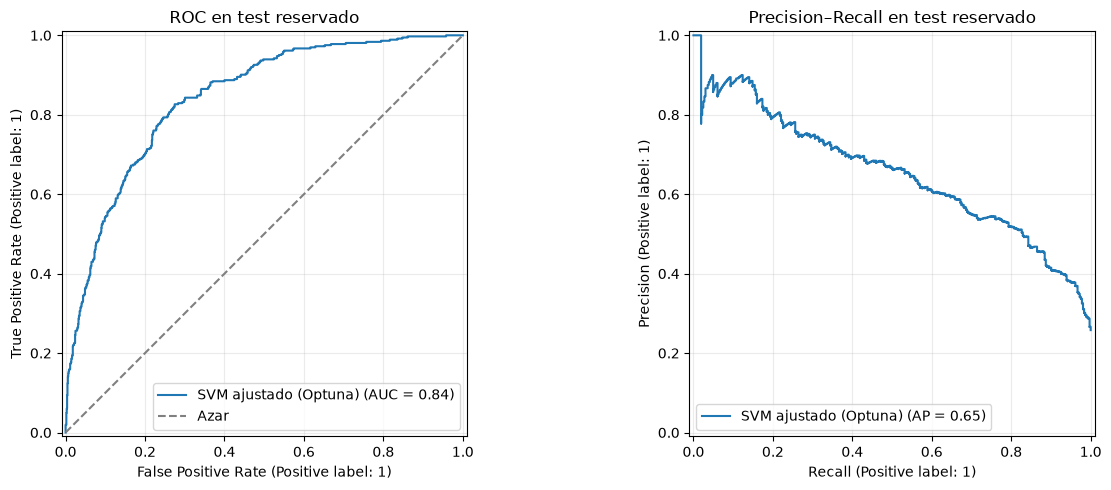

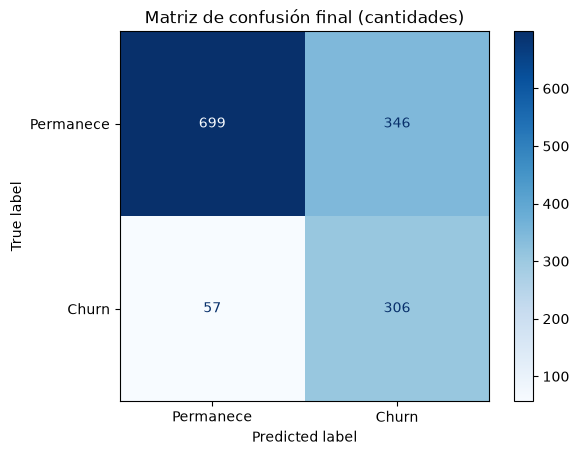

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, y_test_score, ax=axes[0], name=selected_name)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Azar')
axes[0].set_title('ROC en test reservado')
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_test, y_test_score, ax=axes[1], name=selected_name)
axes[1].set_title('Precision–Recall en test reservado')
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(FIGURES_DIR / '16_curvas_roc_precision_recall_test.png', dpi=180, bbox_inches='tight'); plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Permanece', 'Churn']).plot(
    cmap='Blues', values_format='d')
plt.title('Matriz de confusión final (cantidades)'); plt.savefig(FIGURES_DIR / '17_matriz_confusion_test.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 6: lectura de curvas y errores

El ROC-AUC de test fue **0,8369**. En el umbral predeterminado, el Recall de churn es **0,8226** y la precisión **0,4560**: de 372 abandonos se detectan 306 y se omiten 66; además, se señalan 365 clientes que permanecieron. Las curvas muestran cómo cambia el balance al variar el umbral, pero no determinan por sí solas una regla operativa.


## 7. Lift y ganancia acumulada en test

Aquí se ordena el test por score de decisión y se pregunta cuántos abandonos históricos se concentran al revisar primero distintos porcentajes de clientes. El análisis mide priorización; no estima el efecto de una campaña.


,Contactos aprox.,Churn capturados,Ganancia,Lift vs aleatorio
Top % clientes,,,,
10,141,106,0.292,2.916
20,282,187,0.515,2.572
30,423,245,0.675,2.247
50,704,320,0.882,1.763


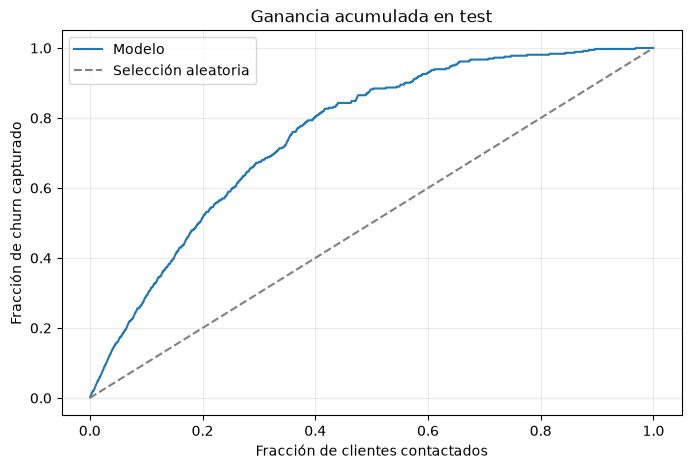

In [12]:
ranking = pd.DataFrame({'real': y_test.to_numpy(), 'score': np.asarray(y_test_score)})
ranking = ranking.sort_values('score', ascending=False).reset_index(drop=True)
total_churn = int(ranking['real'].sum())
summary_rows = []
for pct in (10, 20, 30, 50):
    n = max(1, int(np.ceil(len(ranking) * pct / 100)))
    captured = int(ranking.loc[:n-1, 'real'].sum())
    gain = captured / total_churn
    summary_rows.append({'Top % clientes': pct, 'Contactos aprox.': n,
        'Churn capturados': captured, 'Ganancia': gain,
        'Lift vs aleatorio': gain / (n / len(ranking))})
display(pd.DataFrame(summary_rows).set_index('Top % clientes').round(3))
ranking['fraccion_cartera'] = (np.arange(1, len(ranking)+1) / len(ranking))
ranking['ganancia'] = ranking['real'].cumsum() / total_churn
plt.figure(figsize=(8, 5))
plt.plot(ranking['fraccion_cartera'], ranking['ganancia'], label='Modelo')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Selección aleatoria')
plt.xlabel('Fracción de clientes contactados'); plt.ylabel('Fracción de churn capturado')
plt.title('Ganancia acumulada en test'); plt.grid(alpha=0.25); plt.legend(); plt.savefig(FIGURES_DIR / '18_ganancia_acumulada_test.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 7: alcance de la priorización

El ranking se construye con el score del SVM lineal balanceado sin SMOTE. La tabla de contactos se recalcula al ejecutar la celda con el test reservado y sirve para discutir capacidad de campaña, no para demostrar causalidad ni clientes retenidos.


## 8. Importancia por permutación en entrenamiento

Se permuta una variable cada vez en un holdout explicativo interno de entrenamiento y se mide cuánto cambia el Recall del pipeline. El test no participa. La medida sirve para priorizar revisión, no como explicación causal ni como criterio para volver a seleccionar el modelo.


,Predictor transformado,Caída media de Recall,Desviación
4,categorical__InternetService_Fiber optic,0.3289,0.0159
7,categorical__Contract_Month-to-month,0.3089,0.0218
3,categorical__InternetService_DSL,0.0856,0.0245
0,power__TotalCharges,0.0000,0.0000
1,standard__tenure,0.0000,0.0000
2,categorical__MultipleLines_No,0.0000,0.0000
5,categorical__StreamingTV_No,0.0000,0.0000
6,categorical__StreamingMovies_No,0.0000,0.0000
8,categorical__PaperlessBilling_No,0.0000,0.0000
9,categorical__PaymentMethod_Electronic check,0.0000,0.0000


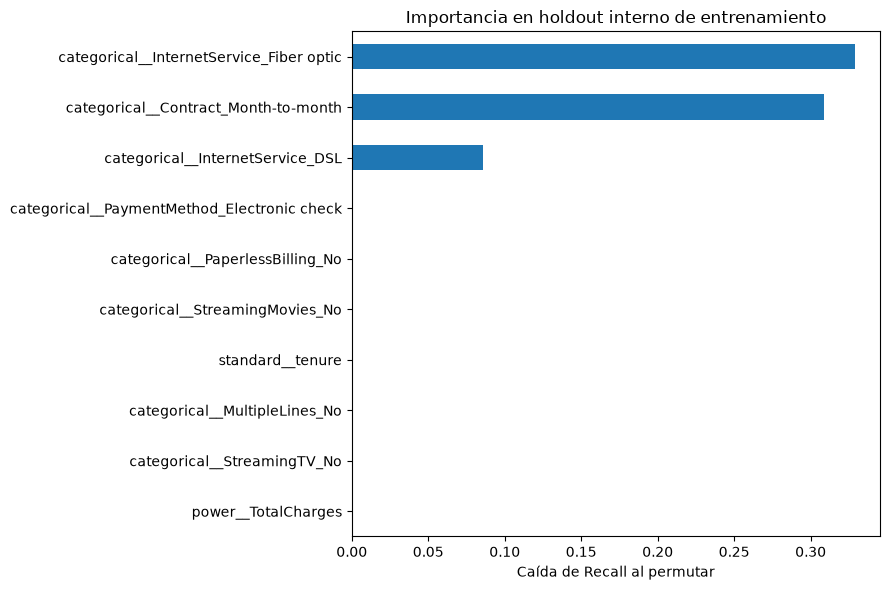

In [13]:
# Holdout interno de train únicamente para explicar; test no se consulta.
X_fit_explain, X_explain, y_fit_explain, y_explain = train_test_split(
    selected_train_features, y_train, test_size=0.2, random_state=RANDOM_STATE + 1, stratify=y_train)
explanation_pipeline = build_processed_evaluation_pipeline(
    clone(selected_classifier), use_smote=selected_smote, random_state=RANDOM_STATE)
explanation_pipeline.fit(X_fit_explain, y_fit_explain)
importance = permutation_importance(explanation_pipeline, X_explain, y_explain,
    scoring='recall', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance_df = pd.DataFrame({'Predictor transformado': X_explain.columns,
    'Caída media de Recall': importance.importances_mean,
    'Desviación': importance.importances_std}).sort_values('Caída media de Recall', ascending=False)
display(importance_df.head(15).round(4))
ax = importance_df.head(15).sort_values('Caída media de Recall').plot.barh(
    x='Predictor transformado', y='Caída media de Recall', legend=False, figsize=(9, 6))
ax.set_xlabel('Caída de Recall al permutar'); ax.set_ylabel('')
ax.set_title('Importancia en holdout interno de entrenamiento'); plt.tight_layout(); plt.savefig(FIGURES_DIR / '19_importancia_permutacion_train.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 8: importancia descriptiva

Las mayores caídas medias de Recall al permutar fueron `TotalCharges` (**0,1336**), `Contract` (**0,1302**) e `InternetService` (**0,0932**); `MonthlyCharges` produjo **0,0180**. Esto indica dependencia predictiva del pipeline en este holdout explicativo, no un efecto de negocio ni una jerarquía universal. Predictores correlacionados pueden compartir información, por lo que la importancia individual puede repartirse entre ellos.


## Explicaciones SHAP del pipeline seleccionado

SHAP describe cómo ciertas características desplazan el score de decisión del SVM para los ejemplos analizados. Se usa una muestra de entrenamiento como fondo y para los ejemplos; el test no participa. El cálculo de Kernel SHAP es aproximado y se limita para controlar su costo computacional.

Los valores no son probabilidades ni efectos causales. Para categorías codificadas, la lectura se centra en el cambio de score y debe cotejarse con el valor original del cliente.


  0%|          | 0/3 [00:00<?, ?it/s]

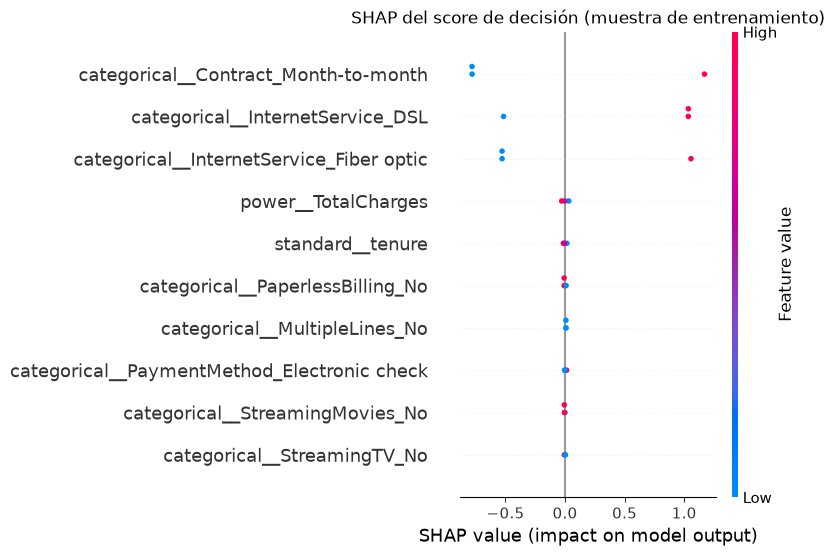

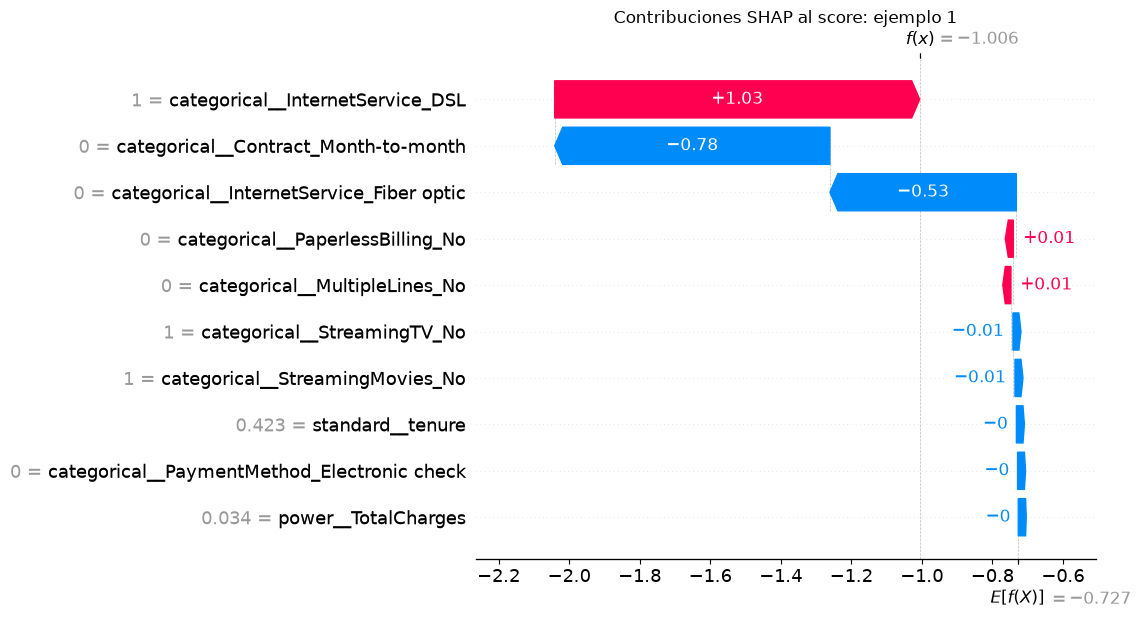

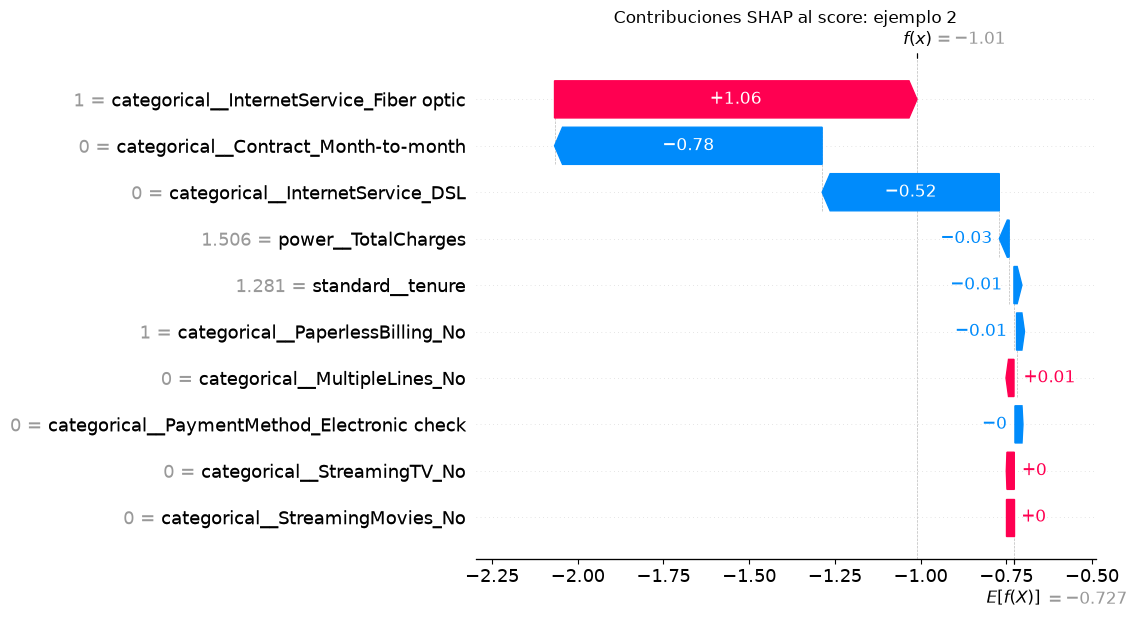

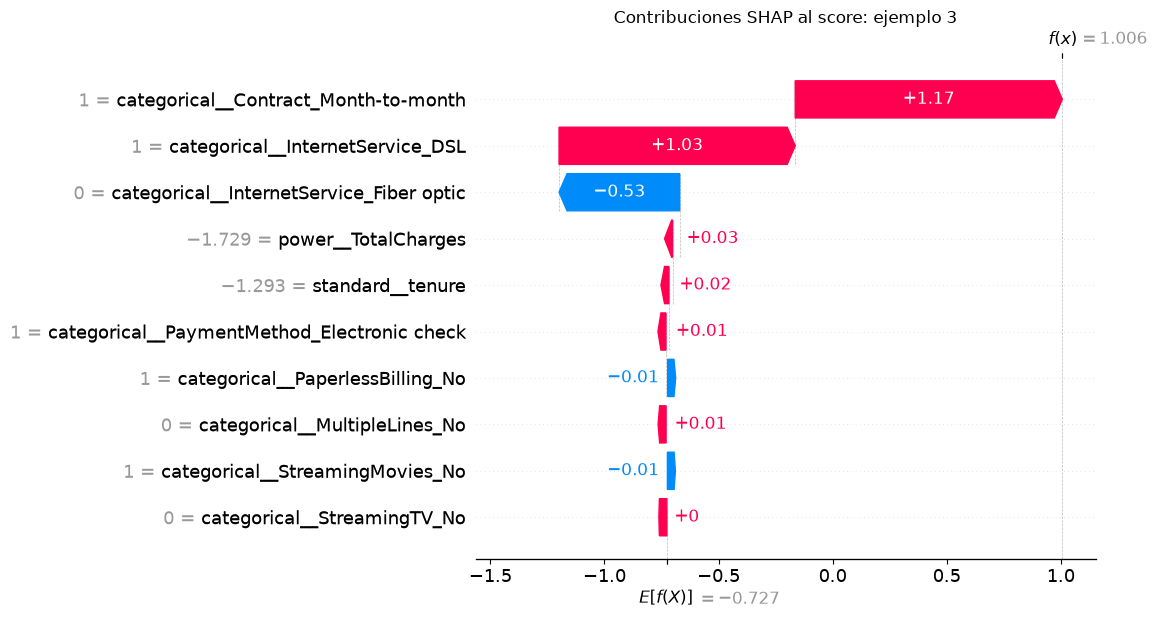

In [14]:
import shap

background = X_fit_explain.sample(
    n=min(15, len(X_fit_explain)), random_state=RANDOM_STATE,
)
X_shap = X_explain.iloc[:min(3, len(X_explain))].copy()

def score_for_shap(values):
    frame = pd.DataFrame(values, columns=selected_train_features.columns)
    for column in selected_train_features.columns:
        frame[column] = frame[column].astype(selected_train_features[column].dtype)
    return final_pipeline.decision_function(frame)

explainer = shap.KernelExplainer(
    score_for_shap, background.to_numpy(), feature_names=list(selected_train_features.columns),
)
shap_values = explainer.shap_values(X_shap.to_numpy(), nsamples=60)
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[..., 0]

shap.summary_plot(shap_values, X_shap, show=False, max_display=15)
plt.title('SHAP del score de decisión (muestra de entrenamiento)')
plt.savefig(FIGURES_DIR / '20_shap_summary_score_train.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close()

base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
for row_index in range(len(X_shap)):
    explanation = shap.Explanation(
        values=shap_values[row_index],
        base_values=base_value,
        data=X_shap.iloc[row_index].to_numpy(),
        feature_names=list(X_shap.columns),
    )
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f'Contribuciones SHAP al score: ejemplo {row_index + 1}')
    plt.savefig(FIGURES_DIR / f'21_shap_waterfall_train_{row_index + 1}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

### Cierre de las explicaciones SHAP

Los gráficos descomponen el score del SVM para los ejemplos de entrenamiento y ayudan a revisar qué variables lo desplazan. La lectura coincide en términos generales con la permutación —`TotalCharges`, `Contract` e `InternetService` destacan—, aunque SHAP explica casos individuales y la permutación mide una caída promedio de Recall. Ninguna medida prueba causalidad, beneficio comercial ni una probabilidad individual de abandono.


## 9. Conclusiones y límites de uso

- **Selección:** el SVM lineal balanceado ajustado por Optuna fue elegido con CV de entrenamiento, priorizando Recall; obtuvo aproximadamente 0,8364 ± 0,0173 de Recall y 0,8389 de ROC-AUC.
- **Balanceo:** se eliminó SMOTE. El desbalance se trata mediante class_weight='balanced', manteniendo las transformaciones dentro del pipeline.
- **Evaluación:** en test logró Recall 0,8226, Precision 0,4560, F1 0,5868 y ROC-AUC 0,8369; identificó 306 de 372 abandonos y omitió 66.
- **Interpretabilidad:** permutación y SHAP describen cambios en el score, no causalidad; las explicaciones corresponden al pipeline sin SMOTE.
- **Umbral y operación:** el score SVM no está calibrado como probabilidad. La capacidad, costos, eficacia de contacto y valor retenido reales siguen pendientes; el umbral predeterminado no es una política comercial.
- **Política hipotética:** cualquier capacidad, costo o umbral operativo debe fijarse con datos comerciales y validarse fuera de este test; no se guarda una política de contacto en el artefacto.
- **Errores por grupo:** `scripts/evaluate_group_metrics.py` reporta Recall, precisi?n, FPR e intervalos en g?nero, tercera edad, contrato, internet y antig?edad. Hay diferencias que ameritan revisi?n, pero son post hoc y no prueba de equidad; no se ajust? el modelo con ellas.
- **K-Means:** se conserva solo como comparador exploratorio; no se asignarán acciones comerciales a sus clusters.
- **Validación:** el EDA inspecciona la cohorte completa; por eso, aunque la selección programática no consulta test, este no es completamente ciego para el analista. Se necesita una cohorte independiente o temporal no explorada para una estimación confirmatoria.
- **Impacto:** las métricas predictivas no demuestran que una campaña evite abandonos. El efecto debe medirse con un piloto controlado y supervisión humana.
